# Laboratorium 3 — Otwarte dane i wartości odstające

**Eksploracja danych** · dr Paweł Gliwny · WFiIS UŁ

Na tych zajęciach:

1. **Część 1** — pobierzesz dane z portalu otwartych danych Łodzi, wczytasz je, zmienisz ich format, policzysz statystyki zbiorcze i zrobisz proste wykresy.
2. **Część 2** — na danych o pacjentach przejdziesz kolejne kroki wykrywania wartości odstających: od najprostszych do bardziej złożonych.

Miejsca do uzupełnienia oznaczone są `# TODO`. Odpowiedzi na pytania wpisuj w komórkach tekstowych oznaczonych ✍️.

> Notatnik po zajęciach umieść w swoim repozytorium na GitHubie.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.float_format", "{:.2f}".format)
plt.rcParams["figure.dpi"] = 100

In [ ]:
def upewnij_sie_ze_jest(nazwa_pliku):
    # W Colabie: jeśli pliku nie ma, otwiera okno wgrywania pliku.
    if Path(nazwa_pliku).exists():
        print(f"Plik {nazwa_pliku} jest na miejscu.")
        return
    try:
        from google.colab import files
        print(f"Wgraj plik {nazwa_pliku}:")
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"Umieść plik {nazwa_pliku} w folderze z notatnikiem.")

---
# Część 1. Dane z portalu otwartych danych Łodzi

Portal: [otwarte.miasto.lodz.pl](https://otwarte.miasto.lodz.pl)

Zaczynamy od wspólnego przykładu — pliku `szkolnictwo_wysze.csv` (szkolnictwo wyższe w Łodzi w latach 2012–2024). Pobierz go z portalu albo od prowadzącego i wgraj do Colaba (ikona folderu po lewej lub komórka poniżej).

In [ ]:
PLIK_LODZ = "szkolnictwo_wysze.csv"
upewnij_sie_ze_jest(PLIK_LODZ)

Plik szkolnictwo_wysze.csv jest na miejscu.


## 1.1 Wczytanie danych

Zanim wywołasz `read_csv`, obejrzyj surowy plik — pierwsze linie tekstu powiedzą, jaki jest separator.

In [ ]:
# podgląd surowego pliku
with open(PLIK_LODZ, encoding="utf-8") as f:
    for _ in range(5):
        print(f.readline().rstrip())

﻿name;rok;wartość;zmienna
Szkolnictwo wyższe;2012;22;uczelnie
Szkolnictwo wyższe;2013;22;uczelnie
Szkolnictwo wyższe;2014;23;uczelnie
Szkolnictwo wyższe;2015;21;uczelnie


In [ ]:
# TODO: wczytaj plik do ramki `df` z właściwym separatorem
df = pd.read_csv(PLIK_LODZ, sep=";")

# TODO: wyświetl pierwsze wiersze, wymiary i typy kolumn
print("Pierwsze wiersze:")
print(df.head())
print("\nWymiary:")
print(df.shape)
print("\nTypy kolumn:")
print(df.dtypes)


Pierwsze wiersze:
                 name   rok  wartość   zmienna
0  Szkolnictwo wyższe  2012       22  uczelnie
1  Szkolnictwo wyższe  2013       22  uczelnie
2  Szkolnictwo wyższe  2014       23  uczelnie
3  Szkolnictwo wyższe  2015       21  uczelnie
4  Szkolnictwo wyższe  2016       20  uczelnie

Wymiary:
(65, 4)

Typy kolumn:
name       object
rok         int64
wartość     int64
zmienna    object
dtype: object


✍️ **Pytanie:** Jaki jest separator? Czy kolumna `wartość` ma typ liczbowy? Czy nazwy kolumn z polskimi znakami wczytały się poprawnie?

* Separator to ;
* Tak int64
* Tak nazwy kolumn z polskimi znakami wczytały się poprawnie

## 1.2 Format długi czy szeroki?

Przypomnienie z wykładu 2: w formacie **długim** każdy wiersz to jedna para (zmienna, wartość); w formacie **szerokim** każda zmienna ma własną kolumnę.

1. Sprawdź, jakie wartości przyjmuje kolumna `zmienna` i ile razy każda występuje.
2. Przekształć dane do formatu szerokiego: wiersze = lata, kolumny = zmienne.

In [ ]:
# TODO: jakie są zmienne i ile mają wierszy?
print(df["zmienna"].value_counts())

# TODO: format szeroki (pivot) — wynik zapisz w `szeroka`
szeroka = df.pivot(index="rok", columns="zmienna", values="wartość")
print("\n",szeroka)
# sam zapis szeroka też się wyświetlał, bo colab ma funkcję automatycznego wyświetlania ostatniej linii
# w przypadku tabel colab dodatkowo wyświetli ją w html

zmienna
uczelnie             13
ogółem               13
kobiety              13
mężczyźni            13
absolwenci ogółem    13
Name: count, dtype: int64

 zmienna  absolwenci ogółem  kobiety  mężczyźni  ogółem  uczelnie
rok                                                             
2012                 24825    55265      36281   91546        22
2013                 22590    50007      33464   83471        22
2014                 21343    48220      32456   80676        23
2015                 19835    45584      30769   76353        21
2016                 17662    44053      29908   73961        20
2017                 19281    42990      29029   72019        22
2018                 17046    39312      26253   65565        20
2019                 15819    38146      26297   64443        19
2020                 14082    39170      26155   65325        18
2021                 14756    39958      26044   66002        17
2022                 14479    38484      26049   64533        18

## 1.3 Czy dane są spójne?

Liczba studentów `ogółem` powinna być sumą `kobiety` i `mężczyźni`. Sprawdź to dla każdego roku.

In [ ]:
# TODO: policz różnicę (kobiety + mężczyźni) − ogółem dla każdego roku
print((szeroka["kobiety"] + szeroka["mężczyźni"]) - szeroka["ogółem"])


rok
2012    0
2013    0
2014    0
2015    0
2016    0
2017    0
2018    0
2019    0
2020    0
2021    0
2022    0
2023    0
2024    0
dtype: int64


## 1.4 Statystyki zbiorcze

1. Policz statystyki opisowe dla wszystkich zmiennych (`describe`).
2. O ile procent zmieniła się każda zmienna między 2012 a 2024 rokiem?
3. Dodaj kolumnę `udzial_kobiet` (udział kobiet wśród studentów) i kolumnę `studenci_na_uczelnie`.

In [ ]:
# TODO: statystyki opisowe
for x in szeroka.columns:
  print(szeroka[x].describe(), "\n")

# lub tabela
display(szeroka.describe())

# TODO: zmiana procentowa 2012 → 2024
# zmiana = (szeroka["x"].loc[2024] - szeroka["x"].loc[2012]) / szeroka["x"].loc[2012] * 100 # konkretna kolumna
zmiana = (szeroka.loc[2024] - szeroka.loc[2012]) / szeroka.loc[2012] * 100
print(f"Zmiana procentowa: {zmiana}%")


# TODO: nowe kolumny
szeroka["udzial_kobiet"] = szeroka["kobiety"] / szeroka["ogółem"]
szeroka["studenci_na_uczelnie"] = szeroka["ogółem"] / szeroka["uczelnie"]

# print(szeroka)
display(szeroka)

count      13.00
mean    17780.54
std      3522.40
min     14082.00
25%     14756.00
50%     17046.00
75%     19835.00
max     24825.00
Name: absolwenci ogółem, dtype: float64 

count      13.00
mean    43010.92
std      5391.05
min     38146.00
25%     39170.00
50%     39958.00
75%     45584.00
max     55265.00
Name: kobiety, dtype: float64 

count      13.00
mean    28793.92
std      3524.63
min     25710.00
25%     26049.00
50%     26297.00
75%     30769.00
max     36281.00
Name: mężczyźni, dtype: float64 

count      13.00
mean    71804.85
std      8900.65
min     64272.00
25%     65297.00
50%     66002.00
75%     76353.00
max     91546.00
Name: ogółem, dtype: float64 

count   13.00
mean    19.54
std      2.44
min     15.00
25%     18.00
50%     20.00
75%     22.00
max     23.00
Name: uczelnie, dtype: float64 

count   13.00
mean     0.60
std      0.00
min      0.59
25%      0.60
50%      0.60
75%      0.60
max      0.61
Name: udzial_kobiet, dtype: float64 

count     13.00
mean  

zmienna,absolwenci ogółem,kobiety,mężczyźni,ogółem,uczelnie,udzial_kobiet,studenci_na_uczelnie
count,13.00,13.00,13.00,13.00,13.00,13.00,13.00
mean,17780.54,43010.92,28793.92,71804.85,19.54,0.60,3689.47
std,3522.40,5391.05,3524.63,8900.65,2.44,0.00,306.77
min,14082.00,38146.00,25710.00,64272.00,15.00,0.59,3273.59
25%,14756.00,39170.00,26049.00,65297.00,18.00,0.60,3507.65
50%,17046.00,39958.00,26297.00,66002.00,20.00,0.60,3635.86
75%,19835.00,45584.00,30769.00,76353.00,22.00,0.60,3841.00
max,24825.00,55265.00,36281.00,91546.00,23.00,0.61,4284.80


Zmiana procentowa: zmienna
absolwenci ogółem      -41.29
kobiety                -30.22
mężczyźni              -29.14
ogółem                 -29.79
uczelnie               -31.82
udzial_kobiet           -0.61
studenci_na_uczelnie     2.97
dtype: float64%


zmienna,absolwenci ogółem,kobiety,mężczyźni,ogółem,uczelnie,udzial_kobiet,studenci_na_uczelnie
rok,,,,,,,
2012,24825,55265,36281,91546,22,0.60,4161.18
2013,22590,50007,33464,83471,22,0.60,3794.14
2014,21343,48220,32456,80676,23,0.60,3507.65
2015,19835,45584,30769,76353,21,0.60,3635.86
2016,17662,44053,29908,73961,20,0.60,3698.05
2017,19281,42990,29029,72019,22,0.60,3273.59
2018,17046,39312,26253,65565,20,0.60,3278.25
2019,15819,38146,26297,64443,19,0.59,3391.74
2020,14082,39170,26155,65325,18,0.60,3629.17


## 1.5 Wykresy

Narysuj trzy wykresy (najlepiej obok siebie, `plt.subplots(1, 3)`):

1. liczba studentów w czasie — osobne linie dla kobiet i mężczyzn,
2. liczba uczelni w czasie,
3. udział kobiet wśród studentów (oś Y od 0 do 1).

Każdy wykres podpisz: tytuł, opisy osi.

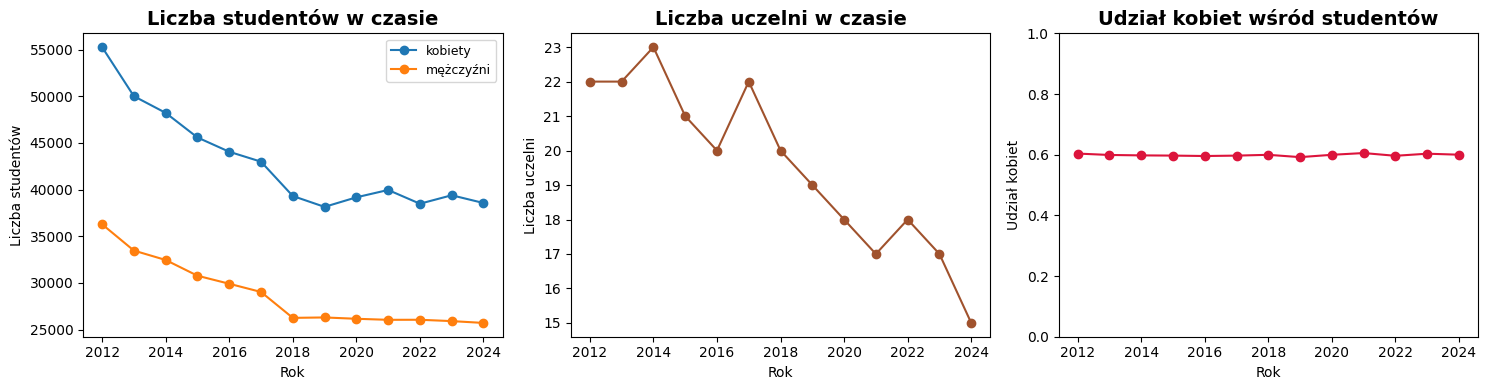

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# TODO: wykres 1 — kobiety i mężczyźni
km_lista = ["kobiety", "mężczyźni"]
for km in km_lista:
  axes[0].plot(szeroka.index, szeroka[km], marker="o", label=km)

axes[0].set_title("Liczba studentów w czasie", fontsize=14, fontweight="bold")
axes[0].set_xlabel("Rok")
axes[0].set_ylabel("Liczba studentów")
axes[0].legend(fontsize=9)


# TODO: wykres 2 — uczelnie
axes[1].plot(szeroka.index, szeroka["uczelnie"], marker="o", color="sienna")

axes[1].set_title("Liczba uczelni w czasie", fontsize=14, fontweight="bold")
axes[1].set_xlabel("Rok")
axes[1].set_ylabel("Liczba uczelni")


# TODO: wykres 3 — udział kobiet
axes[2].plot(szeroka.index, szeroka["udzial_kobiet"], marker="o", color="crimson")

axes[2].set_title("Udział kobiet wśród studentów", fontsize=14, fontweight="bold")
axes[2].set_xlabel("Rok")
axes[2].set_ylabel("Udział kobiet")
axes[2].set_ylim(0, 1)

plt.tight_layout()
plt.show()

✍️ **Wnioski** (3 zdania): co się stało ze szkolnictwem wyższym w Łodzi w latach 2012–2024?

* Możemy wywnioskować, że może nie o tyle co szkolnictwo się pogorszyło, co przestało być popularnym wyborem, być może inne uczelnie oferowały ciekawsze kierunki albo praktyki na start

## 1.6 Zadanie samodzielne: Twój zbiór z portalu Łodzi

Wybierz **inny** zbiór z [otwarte.miasto.lodz.pl](https://otwarte.miasto.lodz.pl) i przejdź te same kroki:

1. Podaj nazwę zbioru, link i datę pobrania.
2. Wczytaj plik (separator? kodowanie? przecinek dziesiętny?).
3. Ustal, czy dane są w formacie długim, czy szerokim; w razie potrzeby przekształć.
4. Sprawdź braki (`isna().sum()`) i spójność danych.
5. Policz statystyki zbiorcze.
6. Zrób 2–3 podpisane wykresy i napisz 2–3 zdania wniosków.

✍️ **Zbiór:** Ludność · **link:** https://otwarte.miasto.lodz.pl/ludnosc/ · **data pobrania:** 12.12 22.10.2026

In [ ]:
# TODO: wczytanie i przegląd Twojego zbioru

PLIK_LUDNOSC = "ludno-wg-pci-w-odzi.csv"
upewnij_sie_ze_jest(PLIK_LUDNOSC)
df_ludnosc = pd.read_csv(PLIK_LUDNOSC, sep=";", decimal=",", thousands=" ")

print(df_ludnosc.head())
# format jest długi, bo powtarza się rok zamiast być swoją kolumną


Plik ludno-wg-pci-w-odzi.csv jest na miejscu.
              name   rok  wartość zmienne
0  Ludność wg płci  1995   823215  ogółem
1  Ludność wg płci  1996   817983  ogółem
2  Ludność wg płci  1997   812317  ogółem
3  Ludność wg płci  1998   806728  ogółem
4  Ludność wg płci  1999   805311  ogółem


zmienne
kobiety      0
mężczyźni    0
ogółem       0
dtype: int64
rok
1995    0
1996    0
1997    0
1998    0
1999    0
2000    0
2001    0
2002    0
2003    0
2004    0
2005    0
2006    0
2007    0
2008    0
2009    0
2010    0
2011    0
2012    0
2013    0
2014    0
2015    0
2016    0
2017    0
2018    0
2019    0
2020    0
2021    0
2022    0
2023    0
2024    0
2025    0
dtype: int64


zmienne,kobiety,mężczyźni,ogółem
count,31.00,31.00,31.00
mean,399031.77,334632.68,733664.45
std,30418.51,26340.21,56737.54
min,347561.00,292329.00,639890.00
25%,374371.50,313482.00,687853.50
50%,398266.00,332367.00,730633.00
75%,424982.00,357149.50,782131.50
max,445712.00,377503.00,823215.00


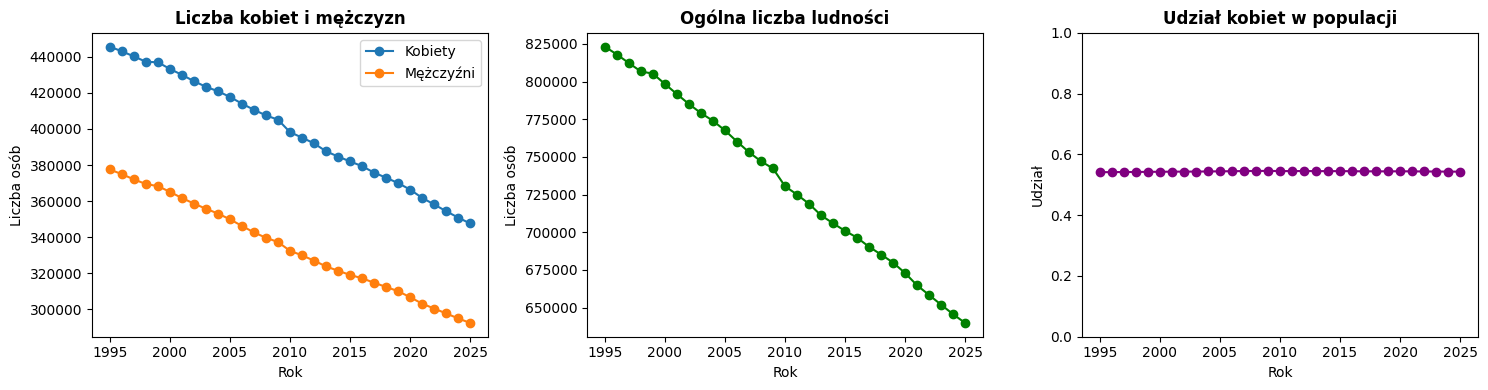

In [ ]:
# TODO: przekształcenia, statystyki i wykresy
szeroka_ludnosc = df_ludnosc.pivot(index="rok", columns="zmienne", values="wartość")

# braki
print(szeroka_ludnosc.isna().sum())
# spójność
print((szeroka_ludnosc["kobiety"] + szeroka_ludnosc["mężczyźni"]) - szeroka_ludnosc["ogółem"])
# statystyki
display(szeroka_ludnosc.describe())

# wykresy
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Wykres 1: Kobiety i mężczyźni w czasie
axes[0].plot(szeroka_ludnosc.index, szeroka_ludnosc["kobiety"], marker="o", label="Kobiety")
axes[0].plot(szeroka_ludnosc.index, szeroka_ludnosc["mężczyźni"], marker="o", label="Mężczyźni")
axes[0].set_title("Liczba kobiet i mężczyzn", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Rok")
axes[0].set_ylabel("Liczba osób")
axes[0].legend()

# Wykres 2: Ogólna liczba ludności
axes[1].plot(szeroka_ludnosc.index, szeroka_ludnosc["ogółem"], marker="o", color="green")
axes[1].set_title("Ogólna liczba ludności", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Rok")
axes[1].set_ylabel("Liczba osób")

# Wykres 3: Udział kobiet w ogólnej liczbie ludności (skala 0–1)
udzial_kobiet = szeroka_ludnosc["kobiety"] / szeroka_ludnosc["ogółem"]
axes[2].plot(szeroka_ludnosc.index, udzial_kobiet, marker="o", color="purple")
axes[2].set_title("Udział kobiet w populacji", fontsize=12, fontweight="bold")
axes[2].set_xlabel("Rok")
axes[2].set_ylabel("Udział")
axes[2].set_ylim(0, 1)

plt.tight_layout()
plt.show()


✍️ **Wnioski:** …
* Liczba ludności z roku na rok spada
* Konkretna płeć nie ma większego spadku, ponieważ udział populacji kobiet jest na podobnym poziomie
* Największy spadek ludności był w 2010 roku

---
# Część 2. Wartości odstające — dane o pacjentach

Zbiór: 3000 pacjentów z kolumnami `age` (wiek), `bmi`, `avg_glucose_level` (średni poziom glukozy we krwi, mg/dl), `hypertension`, `heart_disease`, `work_type` (rodzaj pracy), `smoking_status` (palenie), `stroke` (udar: 1/0) i kilkoma innymi.

> ⚠️ To **dane syntetyczne** — wygenerowane i celowo „zepsute” do ćwiczeń. Nie wyciągamy z nich wniosków medycznych.
>
> Źródło: deepsense.ai, *EDA Benchmark*, zadanie `identify-unusual-values` ([github.com/deepsense-ai/eda-benchmark](https://github.com/deepsense-ai/eda-benchmark)), licencja CC BY-NC-ND 4.0.

Plan — od najprostszej metody do najbardziej złożonej:

| Krok | Metoda |
|---|---|
| 1 | wartości niemożliwe — progi z wiedzy dziedzinowej |
| 2 | wartości skrajne w jednej zmiennej — wykresy, potem IQR, z-score, MAD |
| 3 | nielogiczne kombinacje kategorii — reguły |
| 4 | nietypowe kombinacje liczb — odległość od środka |
| 5 | decyzja: co zrobić z każdą grupą |

In [ ]:
URL = ("https://raw.githubusercontent.com/deepsense-ai/eda-benchmark/main/"
       "tasks/identify-unusual-values/environment/dataset/synthetic_stroke_data.csv")

pacjenci = pd.read_csv(URL)
oryginal = pacjenci.copy()      # kopia surowych danych — przyda się na końcu
pacjenci.head()


,patient_id,gender,age,hypertension,heart_disease,ever_married,work_type,residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,A456281,Male,25.00,0,0,False,student,Urban,77.47,35.66,formerly smoked,0
1,A730553,Male,16.00,0,0,True,student,Urban,83.78,34.76,never smoked,0
2,A800980,Male,19.00,0,0,True,Private,Urban,91.65,25.38,never smoked,0
3,A433166,Male,35.00,0,0,True,Self-employed,Urban,97.09,21.26,never smoked,0
4,A114521,Male,15.00,0,0,True,student,Urban,89.17,22.27,formerly smoked,0


## 2.0 Pierwszy rzut oka

Wyświetl statystyki opisowe kolumn liczbowych `age`, `bmi`, `avg_glucose_level` i narysuj ich histogramy.

count   3000.00
mean      45.25
std       20.83
min        0.67
25%       28.00
50%       49.00
75%       63.00
max       80.00
Name: age, dtype: float64 

count   3000.00
mean      26.29
std       15.88
min       -5.20
25%       21.28
50%       24.70
75%       28.88
max      105.60
Name: bmi, dtype: float64 

count   3000.00
mean     134.00
std      181.27
min      -21.40
25%       85.59
50%      101.40
75%      127.43
max     1254.60
Name: avg_glucose_level, dtype: float64 



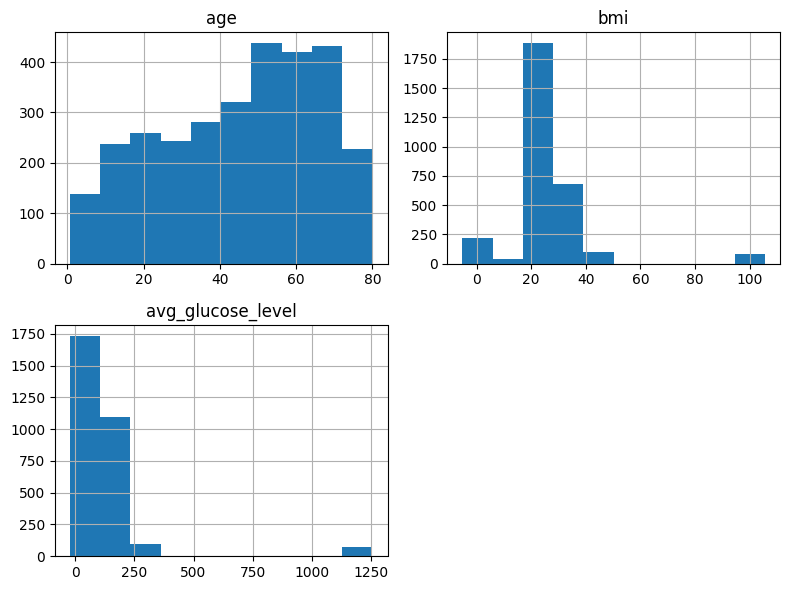

In [ ]:
LICZBOWE = ["age", "bmi", "avg_glucose_level"]

# TODO: statystyki opisowe

for x in LICZBOWE:
  print(pacjenci[x].describe(), "\n")

# TODO: histogramy (np. pacjenci[LICZBOWE].hist(...))
pacjenci[LICZBOWE].hist(figsize=(8, 6))
plt.tight_layout()
plt.show()

✍️ **Pytanie:** Które wartości minimalne i maksymalne są w ogóle *możliwe* u człowieka?

*Odpowiedź:* …
* Zbiór wieku jest poprawny, jeżeli zakładamy, że poprawne jest przedstawienie miesięcy jako jakaś dziesiętna część roku
* BMI ujemne jest niemożliwe, ponieważ człowiek nie może mieć ujemnego wzrostu lub wagi, natomiast BMI 105 choć odstaje jest możliwe, największe zarejestrowane BMI według Wikipedii to 251.1
* Nie możemy mieć ujemnego poziomu glukozy, ponieważ jest to związek chemiczny, który zawsze w nas występuje, ponieważ pobieramy go z pożywienia. Poziom 1254.60 jest możliwy największy zarejestrowany to 2675 mg/dl
* Można jednak przypuszczać, że te wysokie wyniki to błędny szum

## 2.1 Krok 1: wartości niemożliwe

Przyjmujemy progi:

| Zmienna | Zakres możliwy |
|---|---|
| `bmi` | 10–60 |
| `avg_glucose_level` | 20–800 mg/dl |
| `age` | 0–120 lat |

Wartości spoza zakresu to **szum techniczny**, a nie rzadcy pacjenci — zamieniamy je na `NaN`.

1. Utwórz maski `zle_bmi`, `zla_glukoza`, `zly_wiek` (przyda się `Series.between`).
2. Policz, ile wartości jest niemożliwych w każdej kolumnie i ilu pacjentów ma co najmniej jedną taką wartość.
3. Zamień niemożliwe wartości na `NaN`.

In [ ]:
# TODO: maski
zle_bmi = ~pacjenci["bmi"].between(10, 100)
zla_glukoza = ~pacjenci["avg_glucose_level"].between(20, 800)
zly_wiek = ~pacjenci["age"].between(0, 120)

print(f"Liczba BMI spoza zakresu: {zle_bmi.sum()}")
print(f"Liczba glukozy spoza zakresu: {zla_glukoza.sum()}")
print(f"Liczba wieku spoza zakresu: {zly_wiek.sum()}")

pacjenci_ze_bledami = (zle_bmi | zla_glukoza | zly_wiek).sum()
print(f"\nLiczba pacjentów z co najmniej jedną niemożliwą wartością: {pacjenci_ze_bledami}")

# TODO: zamiana na NaN
pacjenci.loc[zle_bmi, "bmi"] = np.nan
pacjenci.loc[zla_glukoza, "avg_glucose_level"] = np.nan
pacjenci.loc[zly_wiek, "age"] = np.nan
# do zadania 2.6
maska_niemozliwe_wartosci = zle_bmi | zla_glukoza | zly_wiek


Liczba BMI spoza zakresu: 300
Liczba glukozy spoza zakresu: 300
Liczba wieku spoza zakresu: 0

Liczba pacjentów z co najmniej jedną niemożliwą wartością: 560


count   3000.00
mean      45.25
std       20.83
min        0.67
25%       28.00
50%       49.00
75%       63.00
max       80.00
Name: age, dtype: float64 

count   2700.00
mean      26.12
std        5.84
min       13.57
25%       21.94
50%       24.98
75%       28.85
max       47.62
Name: bmi, dtype: float64 

count   2700.00
mean     116.84
std       44.45
min       44.76
25%       89.47
50%      103.09
75%      127.84
max      332.91
Name: avg_glucose_level, dtype: float64 



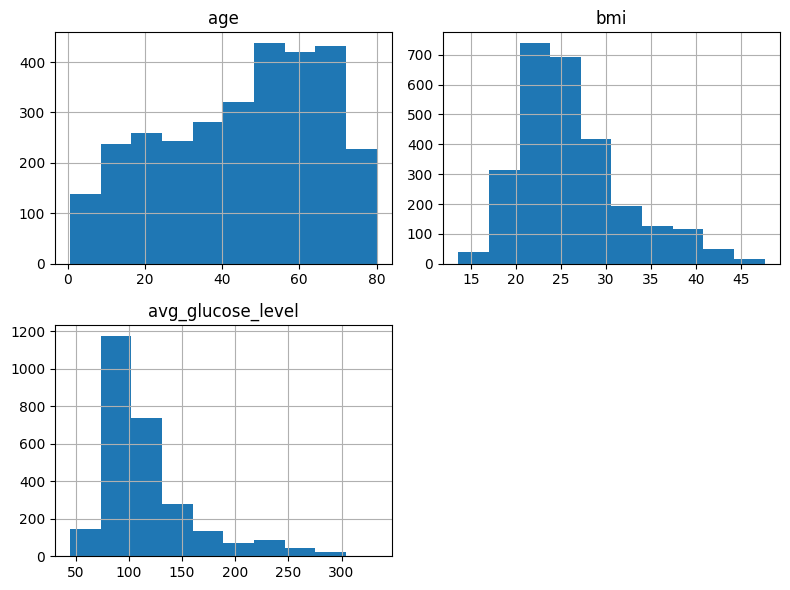

In [ ]:
# TODO: ponownie statystyki opisowe i histogramy — co się zmieniło?
LICZBOWE = ["age", "bmi", "avg_glucose_level"]
for x in LICZBOWE:
  print(pacjenci[x].describe(), "\n")

pacjenci[LICZBOWE].hist(figsize=(8, 6))
plt.tight_layout()
plt.show()

* Niepoprawne wartości zostały zmienione na Nan, więc nie są brane pod uwagę przy liczeniu statystyk i tworzeniu histogramów
* Wykresy mają teraz mniejsze zakresy osi, dzięki czemu lepiej oddają rzeczywistość i są czystelniejsze do tworzenia analiz

## 2.2 Krok 2a: wartości skrajne w jednej zmiennej — wykresy

Zanim cokolwiek policzysz, **obejrzyj** dane.

1. Narysuj obok siebie poziome wykresy pudełkowe dla `bmi` i `avg_glucose_level` (`plt.subplots(1, 2)`, `ax.boxplot(..., orientation="horizontal")`). Pamiętaj o `dropna()`.
2. Narysuj obok siebie dwa wykresy punktowe: `age` × `avg_glucose_level` i `age` × `bmi`.

Podpisz osie (z jednostkami) i nadaj tytuły.

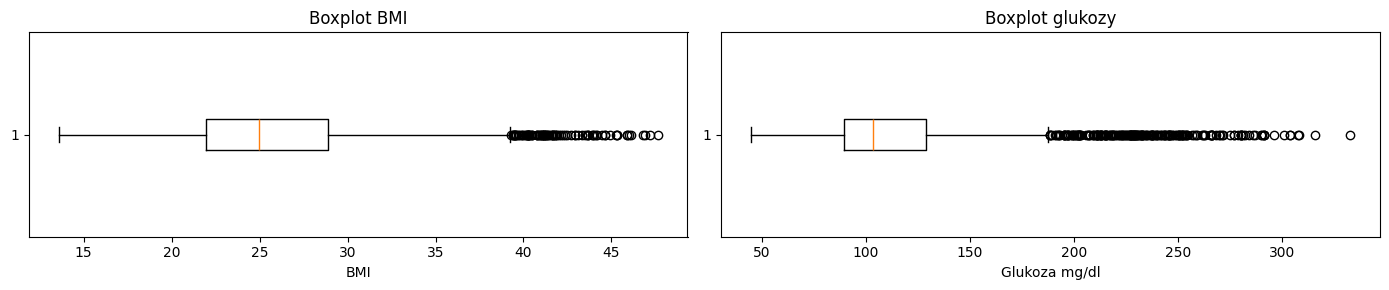

Liczba kropek (outliers) wyciągnięta z boxplota: 210


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3))
pacjenci_bez_brakow = pacjenci.dropna()

# TODO: wykresy pudełkowe bmi i glukozy
axes[0].boxplot(pacjenci_bez_brakow["bmi"], orientation="horizontal")
axes[0].set_title("Boxplot BMI")
axes[0].set_xlabel("BMI")

bp_glukoza = axes[1].boxplot(pacjenci_bez_brakow["avg_glucose_level"], orientation="horizontal")
axes[1].set_title("Boxplot glukozy")
axes[1].set_xlabel("Glukoza mg/dl")

plt.tight_layout()
plt.show()


# do zadania 2.3
kropki = bp_glukoza['fliers'][0].get_xdata()
liczba_kropek = len(kropki)
print(f"Liczba kropek (outliers) wyciągnięta z boxplota: {liczba_kropek}")




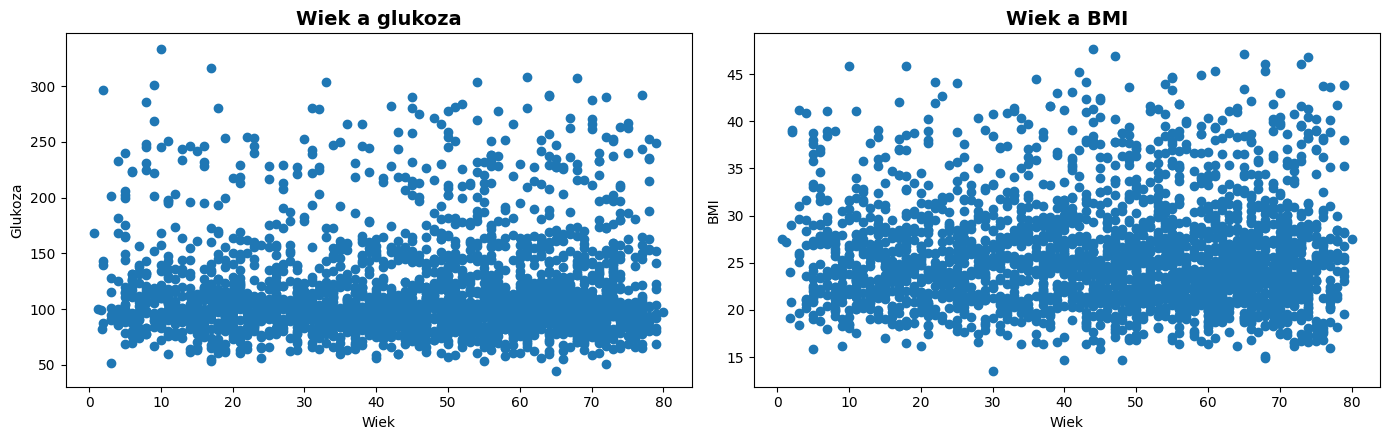

In [ ]:
# TODO: wykresy punktowe age × glukoza i age × bmi
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].scatter(pacjenci_bez_brakow["age"], pacjenci_bez_brakow["avg_glucose_level"])
axes[0].set_title("Wiek a glukoza", fontsize=14, fontweight="bold")
axes[0].set_xlabel("Wiek")
axes[0].set_ylabel("Glukoza")
axes[1].scatter(pacjenci_bez_brakow["age"], pacjenci_bez_brakow["bmi"])
axes[1].set_title("Wiek a BMI", fontsize=14, fontweight="bold")
axes[1].set_xlabel("Wiek")
axes[1].set_ylabel("BMI")

plt.tight_layout()
plt.show()

✍️ **Pytania:**
1. Dla której zmiennej jest więcej punktów poza wąsami? Czy leżą po obu stronach pudełka, czy tylko po jednej?
2. Na wykresie punktowym: czy wysokie wartości glukozy występują tylko w określonym wieku? Czy 10-latek ze średnią glukozą ponad 300 mg/dl to błąd, czy rzadki przypadek?

*Odpowiedź:* …
1. Punkty poza wąsami częściej występują dla glukoza. Obie zmienne są tylko po jednej stronie pudełka, ponieważ nie mamy ujemnych wartości.
2. Wysokie wartości glukozy zwiększają się wraz z wiekiem, ale występują też regularnie dla młodszych osób. Jednak poziom 300 mg/dl dla 10-latka jest bardzo rzadko spotykany, więc zaliczamy go jako błąd.


## 2.3 Krok 2b: wartości skrajne w jednej zmiennej — metody liczbowe

Napisz trzy funkcje, które dla kolumny `s` zwracają maskę (`True` = wartość odstająca):

- `maska_iqr(s, k=1.5)` — poza $[Q_1 - k \cdot IQR,\; Q_3 + k \cdot IQR]$,
- `maska_z(s, prog=3)` — $|z| > prog$, gdzie $z = (x - \bar{x}) / s$,
- `maska_mad(s, prog=3.5)` — odporny z-score $|0{,}6745 \cdot (x - \text{med}) / \text{MAD}| > prog$.

Braki (`NaN`) nie powinny być oznaczane jako odstające.

In [ ]:
def maska_iqr(s, k=1.5):
  q1 = s.quantile(0.25)
  q3 = s.quantile(0.75)
  iqr = q3 - q1
  dolna = q1 - k * iqr
  gorna = q3 + k * iqr
  return (s < dolna) | (s > gorna)

def maska_z(s, prog=3):
  srednia = s.mean()
  std = s.std()
  if std == 0 or pd.isna(std):
      return pd.Series(False, index=s.index)
  z = (s - srednia).abs() / std
  return z > prog

def maska_mad(s, prog=3.5):
  mediana = s.median()
  mad = (s - mediana).abs().median()
  if mad == 0 or pd.isna(mad):
      return pd.Series(False, index=s.index)
  z_mod = 0.6745 * (s - mediana).abs() / mad
  return z_mod > prog

Zbuduj tabelę porównawczą: wiersze = zmienne (`age`, `bmi`, `avg_glucose_level`), kolumny = metody (IQR 1,5, IQR 3, z-score, MAD), wartości = liczba wykrytych obserwacji. Dodaj kolumnę ze **skośnością** (`skew`).

In [ ]:
# TODO: tabela porównawcza `porownanie`
wierszeP = ["age", "bmi", "avg_glucose_level"]
wyniki= {}

for kol in wierszeP:
    s = pacjenci_bez_brakow[kol]

    wyniki[kol] = {
        "IQR 1.5": maska_iqr(s, k=1.5).sum(),
        "IQR 3": maska_iqr(s, k=3).sum(),
        "z-score": maska_z(s, prog=3).sum(),
        "MAD": maska_mad(s, prog=3.5).sum(),
        "skew": s.skew()
    }

porownanie = pd.DataFrame(wyniki).T
porownanie

,IQR 1.5,IQR 3,z-score,MAD,skew
age,0.00,0.00,0.00,0.00,-0.34
bmi,89.00,0.00,23.00,29.00,0.99
avg_glucose_level,210.00,64.00,54.00,206.00,1.78


✍️ **Pytanie:** Dlaczego dla glukozy metody dają tak różne wyniki, a dla wieku żadna nic nie wykrywa? Spójrz na skośność i histogramy.

*Odpowiedź:* …
* Wiek nic nie wykrywa, ponieważ nie było w nim wartości skrajnych i błędnych, najwyższa wartość 80 lat mieściła się w zakrezie 0, 80
* Jedyne co mamy to skośność -0.34, czyli mamy więcej wartości po jednej stronie i faktycznie mamy więcej osób po prawej stronie wykresu, więcej starszych osób
* Glukoza ma tak odmienne wartości, ponieważ większość osób ma poprawny poziom glukozy, a u chorych na cukrzycę mamy duże skoki
* Z-score jest wrażliwy na skrajne wartości przez co może wykryć mniej lub zupełnie inaczej niż metody odporne
* MAD i IQR opierają się na medianie i kwartylach, które są odporne na ekstremalne wartości. Dlatego IQR z różnymi współczynnikami ma inną liczbę punktów, dla 1.5 złapie wartości w normie, ale podwyższone, a dla 3 ekstrema

### Wykres: zaznacz wartości odstające

Powtórz wykres punktowy `age` × `avg_glucose_level`, ale tym razem:

- zaznacz innym kolorem pacjentów, których glukoza jest odstająca według `maska_iqr` (i podaj ich liczbę w legendzie),
- narysuj poziomą linię przerywaną na górnej granicy $Q_3 + 1{,}5 \cdot IQR$ (`ax.axhline`).

Sprawdź: czy liczba punktów nad linią zgadza się z liczbą punktów poza wąsem na wykresie pudełkowym?

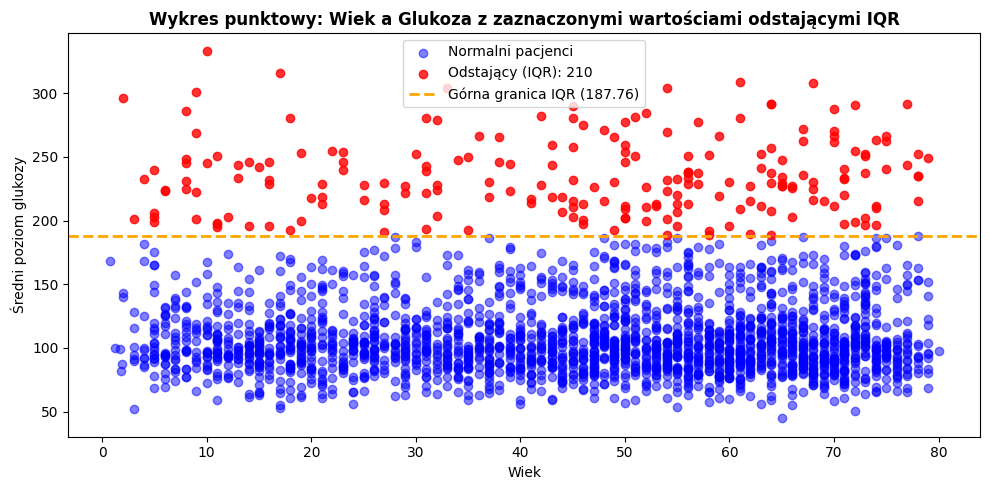

Liczba punktów uznana za odstającą przez IQR: 210


In [ ]:
# TODO: wykres punktowy z zaznaczonymi wartościami odstającymi
s_glukoza = pacjenci_bez_brakow["avg_glucose_level"]
maska_odstajace = maska_iqr(s_glukoza, k=1.5)
liczba_odstajacych = maska_odstajace.sum()

q1 = s_glukoza.quantile(0.25)
q3 = s_glukoza.quantile(0.75)
iqr = q3 - q1
gorna_granica = q3 + 1.5 * iqr

fig, ax = plt.subplots(figsize=(10, 5))

normalni = pacjenci_bez_brakow[~maska_odstajace]
odstajace = pacjenci_bez_brakow[maska_odstajace]

ax.scatter(normalni["age"], normalni["avg_glucose_level"], color="blue", alpha=0.5, label="Normalni pacjenci")
ax.scatter(odstajace["age"], odstajace["avg_glucose_level"], color="red", alpha=0.8, label=f"Odstający (IQR): {liczba_odstajacych}")

ax.axhline(y=gorna_granica, color="orange", linestyle="--", linewidth=2, label=f"Górna granica IQR ({gorna_granica:.2f})")

ax.set_title("Wykres punktowy: Wiek a Glukoza z zaznaczonymi wartościami odstającymi IQR", fontsize=12, fontweight="bold")
ax.set_xlabel("Wiek")
ax.set_ylabel("Średni poziom glukozy")
ax.legend()

plt.tight_layout()
plt.show()

print(f"Liczba punktów uznana za odstającą przez IQR: {liczba_odstajacych}")


Tak liczba punktów (210) zgadza się

### Czy wartość odstająca niesie informację?

Wysoki poziom glukozy może być związany z udarem. Porównaj odsetek udarów (`stroke`) wśród pacjentów z glukozą odstającą (IQR 1,5) i wśród pozostałych. Narysuj wykres pudełkowy glukozy w podziale na `stroke`.

Odsetek udarów u pacjentów z odstającą glukozą: 21.90%
Odsetek udarów u pozostałych pacjentów: 20.49%


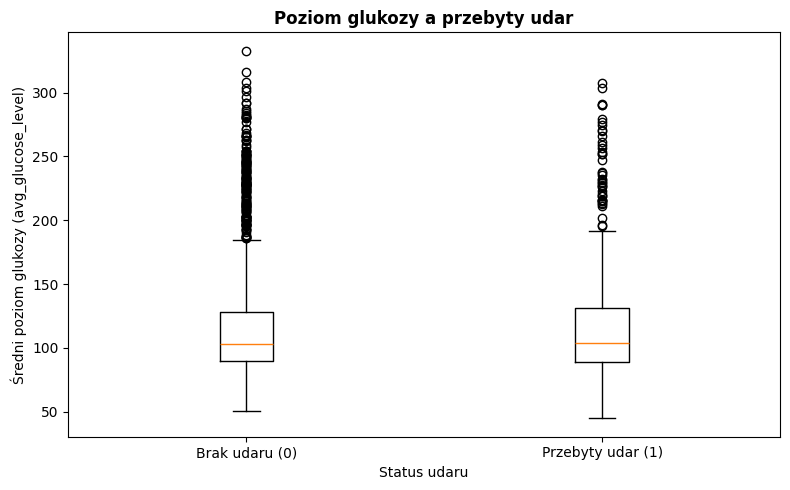

In [ ]:
# TODO: odsetek udarów w obu grupach
s_glukoza = pacjenci_bez_brakow["avg_glucose_level"]
maska_odstajace_iqr = maska_iqr(s_glukoza, k=1.5)

grupa_odstajaca = pacjenci_bez_brakow[maska_odstajace_iqr]
grupa_pozostala = pacjenci_bez_brakow[~maska_odstajace_iqr]

odsetek_odstajace = grupa_odstajaca["stroke"].mean() * 100
odsetek_pozostale = grupa_pozostala["stroke"].mean() * 100

print(f"Odsetek udarów u pacjentów z odstającą glukozą: {odsetek_odstajace:.2f}%")
print(f"Odsetek udarów u pozostałych pacjentów: {odsetek_pozostale:.2f}%")

# TODO: boxplot glukozy w podziale na stroke
glukoza_bez_udaru = pacjenci_bez_brakow[pacjenci_bez_brakow["stroke"] == 0]["avg_glucose_level"]
glukoza_z_udarem = pacjenci_bez_brakow[pacjenci_bez_brakow["stroke"] == 1]["avg_glucose_level"]

fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot([glukoza_bez_udaru, glukoza_z_udarem], tick_labels=["Brak udaru (0)", "Przebyty udar (1)"])

ax.set_title("Poziom glukozy a przebyty udar", fontsize=12, fontweight="bold")
ax.set_ylabel("Średni poziom glukozy (avg_glucose_level)")
ax.set_xlabel("Status udaru")

plt.tight_layout()
plt.show()



✍️ **Pytanie:** Czy pacjentów z wysoką glukozą należy usunąć z danych, jeśli chcemy przewidywać udar?

*Odpowiedź:* …
* Nie, ponieważ dane zostały już oczyszczone, więc wysoki wynik glukozy to cenna wskazówka

## 2.4 Krok 3: nielogiczne kombinacje kategorii

Każda wartość osobno może być poprawna („dziecko”, „pali”), a niemożliwa jest dopiero ich kombinacja.

1. Zrób tabelę krzyżową `work_type` × `smoking_status` (`pd.crosstab`). Co jest podejrzane?
2. Utwórz maski:
   - `dziecko_pali` — `work_type == "children"` i `smoking_status` to `"smokes"` lub `"formerly smoked"`,
   - `maluch_student` — wiek ≤ 3 lata i `work_type == "student"`.
3. Wyświetl znalezionych pacjentów.

In [ ]:
# TODO: tabela krzyżowa
tabela_krzyzowa = pd.crosstab(pacjenci_bez_brakow["work_type"], pacjenci_bez_brakow["smoking_status"])
display(tabela_krzyzowa)
# podejrzane jest, że dzieci mają w kolumnie smokes wartość 10
# dziecko i palacz osobno są poprawne, ale razem nie mają sensu

# TODO: maski
dziecko_pali = (pacjenci_bez_brakow["work_type"] == "children") & (
    pacjenci_bez_brakow["smoking_status"].isin(["smokes", "formerly smoked"]))

maluch_student = (pacjenci_bez_brakow["age"] <= 3) & (
    pacjenci_bez_brakow["work_type"] == "student")

kombinacja  = dziecko_pali | maluch_student
znalezieni = pacjenci_bez_brakow[kombinacja]
print("Ilość", len(znalezieni))
display(znalezieni)


smoking_status,Unknown,formerly smoked,never smoked,smokes
work_type,,,,
Govt_job,13,54,82,56
Never_worked,1,21,29,26
Private,57,354,484,367
Self-employed,14,110,130,116
children,15,0,218,10
student,15,50,160,58


Ilość 11


,patient_id,gender,age,hypertension,heart_disease,ever_married,work_type,residence_type,avg_glucose_level,bmi,smoking_status,stroke
52,A582477,Female,1.80,0,0,False,student,Rural,82.20,24.05,formerly smoked,0
111,A678646,Female,9.00,0,0,False,children,Rural,96.59,22.24,smokes,0
290,A844121,Male,13.00,0,0,False,children,Urban,163.31,20.14,smokes,0
336,A135365,Female,12.00,0,0,False,children,Urban,135.59,27.15,smokes,0
361,A843508,Male,2.00,0,0,False,children,Urban,143.14,39.11,smokes,0
613,A892803,Male,13.00,0,0,False,children,Urban,132.17,25.04,smokes,0
741,A560170,Male,13.00,0,0,False,children,Urban,243.95,25.59,smokes,0
767,A390530,Male,13.00,0,0,False,children,Urban,91.28,28.47,smokes,0
782,A383975,Female,9.00,0,0,False,children,Urban,222.47,25.14,smokes,0
942,A929594,Female,8.00,0,0,False,children,Urban,108.35,19.93,smokes,0


✍️ **Pytanie:** Czy IQR albo z-score mogłyby wykryć te przypadki? Dlaczego?

*Odpowiedź:* …
* Nie ponieważ, te metody są dla danych liczbowych a nie tekstowych, którymi są kategorie jak pali, nie pali, palił. Dlatego korzystamy tu z tabeli krzyżowej by szybko znaleźć niepoprawne kombinacje

## 2.5 Krok 4: nietypowe kombinacje liczb — odległość od środka

Liczymy kwadrat **odległości euklidesowej** każdego pacjenta od środka danych, po standaryzacji cech:

$$d^2 = \sum_j \left(\frac{x_j - \bar{x}_j}{s_j}\right)^2$$

Dla danych o rozkładzie normalnym $d^2$ ma rozkład $\chi^2$ z $p$ stopniami swobody ($p$ = liczba cech), więc próg bierzemy z kwantyla 0,99.

1. Weź kolumny `LICZBOWE` bez braków (`dropna`) → `X`.
2. Wystandaryzuj je i policz `d2`.
3. Wyznacz próg `chi2.ppf(0.99, df=3)` i policz, ilu pacjentów go przekracza.
4. Sprawdź, **która cecha** ma największy udział w $d^2$ u tych pacjentów (`idxmax(axis=1)` na kwadratach z-score'ów).

In [ ]:
from scipy.stats import chi2

# TODO
LICZBOWE = ["age", "bmi", "avg_glucose_level"]
X = pacjenci_bez_brakow[LICZBOWE].dropna()
Z = (X - X.mean()) / X.std()
d2 = (Z ** 2).sum(axis=1)
prog = chi2.ppf(0.99, df=3)

maska_wielowymiarowi_odstajacy = d2 > prog
liczba_przekraczajacych = maska_wielowymiarowi_odstajacy.sum()

print(f"Wartość progu chi2 (0.99, df=3): {prog:.4f}")
print(f"Liczba pacjentów przekraczających próg: {liczba_przekraczajacych}")

najwiekszy_udzial = Z[maska_wielowymiarowi_odstajacy].idxmax(axis=1)
print("\nNajczęstsze cechy powodujące odstawanie u tych pacjentów:")
print(najwiekszy_udzial.value_counts())

Wartość progu chi2 (0.99, df=3): 11.3449
Liczba pacjentów przekraczających próg: 73

Najczęstsze cechy powodujące odstawanie u tych pacjentów:
avg_glucose_level    54
bmi                  19
Name: count, dtype: int64


Glukoza jest silnie prawoskośna, więc odległość wskazuje głównie jej długi ogon. Powtórz obliczenia po zlogarytmowaniu glukozy (`np.log`) i porównaj liczbę odstających. Narysuj wykres punktowy `bmi` × `avg_glucose_level`, zaznaczając pacjentów odstających po transformacji.

Próg chi2 (0.99, df=3): 11.3449
Liczba odstających po zlogarytmowaniu glukozy: 31


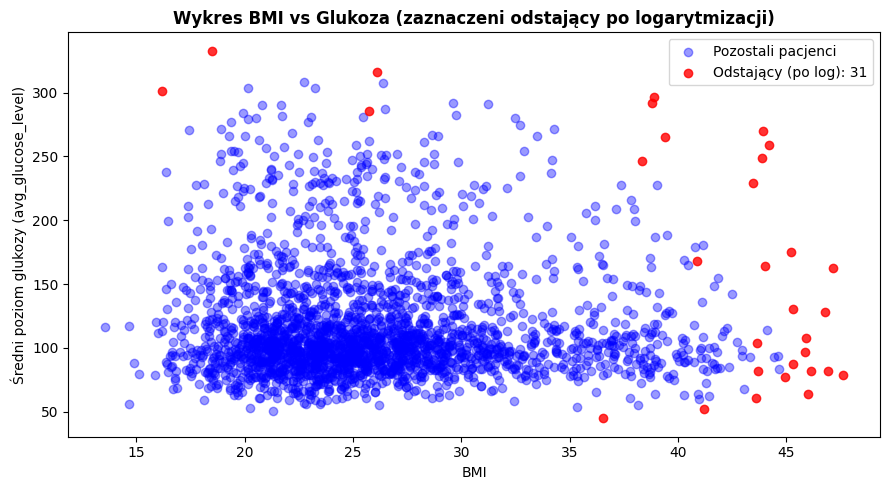

,age,bmi,avg_glucose_level
age,1.00,0.02,0.01
bmi,0.02,1.00,-0.02
avg_glucose_level,0.01,-0.02,1.00


In [ ]:
# TODO: X_log, Z_log, d2_log i liczba odstających
df_log = pacjenci_bez_brakow.copy()
df_log["log_glucose"] = np.log(df_log["avg_glucose_level"])

kolumny_log = ["age", "bmi", "log_glucose"]
X_log = df_log[kolumny_log]
Z_log = (X_log - X_log.mean()) / X_log.std()
d2_log = (Z_log ** 2).sum(axis=1)

prog_log = chi2.ppf(0.99, df=3)
maska_odstajacych_log = d2_log > prog_log
liczba_odstajacych_log = maska_odstajacych_log.sum()

print(f"Próg chi2 (0.99, df=3): {prog_log:.4f}")
print(f"Liczba odstających po zlogarytmowaniu glukozy: {liczba_odstajacych_log}")

# TODO: wykres punktowy
fig, ax = plt.subplots(figsize=(9, 5))

normalni_log = df_log[~maska_odstajacych_log]
odstajace_log = df_log[maska_odstajacych_log]

ax.scatter(normalni_log["bmi"], normalni_log["avg_glucose_level"], color="blue", alpha=0.4, label="Pozostali pacjenci")
ax.scatter(odstajace_log["bmi"], odstajace_log["avg_glucose_level"], color="red", alpha=0.8, label=f"Odstający (po log): {liczba_odstajacych_log}")

ax.set_title("Wykres BMI vs Glukoza (zaznaczeni odstający po logarytmizacji)", fontsize=12, fontweight="bold")
ax.set_xlabel("BMI")
ax.set_ylabel("Średni poziom glukozy (avg_glucose_level)")
ax.legend()

plt.tight_layout()
plt.show()

X.corr()

✍️ **Pytanie:** Wiek, BMI i glukoza są tu prawie nieskorelowane (sprawdź `X.corr()`). Czy w takiej sytuacji odległość Mahalanobisa dałaby coś więcej niż euklidesowa?

*Odpowiedź:* …
* Nie, ponieważ dane są standaryzowane i nieskorelowane, a Mahalanobis polega na korelacji, by dostać inne wyniki, a w tej sytuacji daje bardzo podobne do euklidesa

### Dla chętnych: Isolation Forest

Użyj `sklearn.ensemble.IsolationForest` (`contamination=0.01`, `random_state=0`) na `X_log`. Ilu pacjentów wskazuje jednocześnie Isolation Forest i odległość `d2_log`?

In [ ]:
# TODO (dla chętnych)
from sklearn.ensemble import IsolationForest

iso = IsolationForest(contamination=0.01, random_state=0)
pred_iso = iso.fit_predict(X_log)
maska_iso = (pred_iso == -1)

wspolni_pacjenci = maska_iso & maska_odstajacych_log
liczba_wspolnych = wspolni_pacjenci.sum()

print(f"Liczba pacjentów wskazanych przez obie metody jednocześnie: {liczba_wspolnych}")

Liczba pacjentów wskazanych przez obie metody jednocześnie: 19


## 2.6 Krok 5: podsumowanie i decyzja

Zbierz wyniki wszystkich kroków w jednej ramce `flagi` (jeden wiersz na pacjenta, indeks jak w `oryginal`) z kolumnami logicznymi:

- `niemozliwa_wartosc` (krok 1),
- `glukoza_iqr` (krok 2, IQR 1,5 dla glukozy),
- `nielogiczna_kategoria` (krok 3),
- `odlegly_od_srodka` (krok 4, `d2_log`; pacjenci bez obliczonej odległości → `False`).

Policz, ilu pacjentów ma każdą flagę i ilu ma co najmniej jedną.

In [ ]:
# TODO: ramka flagi
df_flag = pd.DataFrame(index=oryginal.index)

df_flag["niemozliwa_wartosc"] = maska_niemozliwe_wartosci
df_flag["glukoza_iqr"] = maska_odstajace_iqr
df_flag["nielogiczna_kategoria"] = kombinacja
df_flag["odlegly_od_srodka"] = False
df_flag.loc[X_log.index, "odlegly_od_srodka"] = maska_odstajacych_log

df_flag["co_najmniej_jedna_flaga"] = df_flag.any(axis=1)

podsumowanie = df_flag.sum()
print(podsumowanie)


niemozliwa_wartosc         560
glukoza_iqr                210
nielogiczna_kategoria       11
odlegly_od_srodka           31
co_najmniej_jedna_flaga    798
dtype: object


✍️ **Decyzja:** dla każdej grupy zaproponuj strategię i uzasadnij ją jednym zdaniem.

| Grupa | Strategia (poprawić / NaN / usunąć / przyciąć / log / zostawić / flaga) | Uzasadnienie |
|---|---|---|
| wartości niemożliwe | Nan lub usunąć | Bo są to błędy pomiarowe lub szum |
| wysoka glukoza (IQR) | zostawić | Bo są to ważne wskazówki |
| nielogiczne kategorie | Nan lub usunąć | Bo to błędy |
| odlegli od środka | zostawić lub flaga | Bo mogą pokazać bardzo rzadkie przypadki medyczne |